In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans

In [2]:
df = pd.read_csv('/content/Mall_Customers.csv')

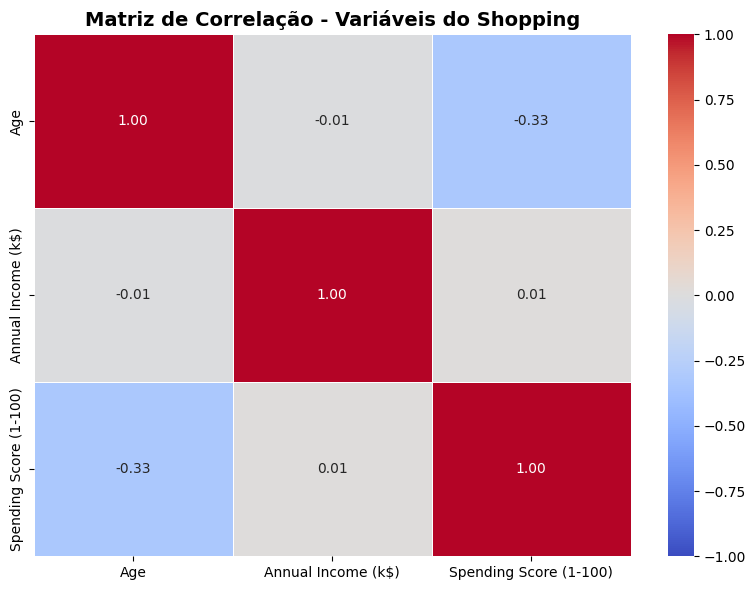

In [3]:
# 2. Preparar os dados para a correlação
# Precisamos remover o CustomerID (pois é só um número de registro, não tem valor matemático)
# e o Gender (pois é texto/categórico e a correlação padrão exige números)
df_numerico = df.drop(['CustomerID', 'Gender'], axis=1)

# 3. Calcular a matriz de correlação (Correlação de Pearson)
matriz_correlacao = df_numerico.corr()

# 4. Criar o gráfico (Heatmap)
plt.figure(figsize=(8, 6))

# O annot=True coloca os números dentro dos quadradinhos
# O cmap='coolwarm' usa azul para correlações negativas e vermelho para positivas
sns.heatmap(matriz_correlacao, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5, vmin=-1, vmax=1)

plt.title('Matriz de Correlação - Variáveis do Shopping', fontsize=14, fontweight='bold')
plt.tight_layout()

# Mostrar o gráfico
plt.show()

In [4]:
# 2. Selecionar as variáveis (d=2) para o nosso estudo de caso
# Vamos usar a Renda Anual (índice 3) e a Pontuação de Gastos (índice 4)
X = df[['Annual Income (k$)', 'Spending Score (1-100)']].values

In [5]:
# 3. Configurar e treinar o modelo K-means
# k=5 (n_clusters=5) conforme definimos no artigo
kmeans = KMeans(n_clusters=5, init='k-means++', random_state=42)

In [6]:
# O comando fit_predict faz o treinamento e já diz a qual cluster cada cliente pertence
y_kmeans = kmeans.fit_predict(X)

In [7]:
# 4. Criar o gráfico (Ideal para colocar no seu artigo da SBC!)
plt.figure(figsize=(10, 6))

<Figure size 1000x600 with 0 Axes>

<Figure size 1000x600 with 0 Axes>

In [8]:
# Cores para os nossos 5 clusters
cores = ['#FF9999', '#66B2FF', '#99FF99', '#FFCC99', '#c2c2f0']
nomes_clusters = ['Econômicos', 'Padrão', 'Alvo (Alta Renda/Gasto)', 'Cuidadosos', 'Impulsivos']

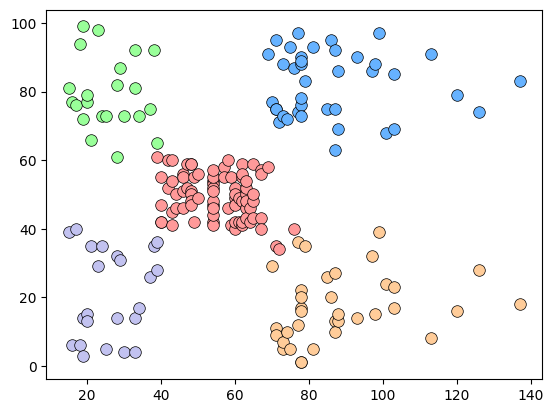

In [9]:
#Plotar os pontos de cada cluster
for i in range(5):
    plt.scatter(X[y_kmeans == i, 0], X[y_kmeans == i, 1],
                s=70, c=cores[i], label=nomes_clusters[i], edgecolors='black', linewidth=0.5)

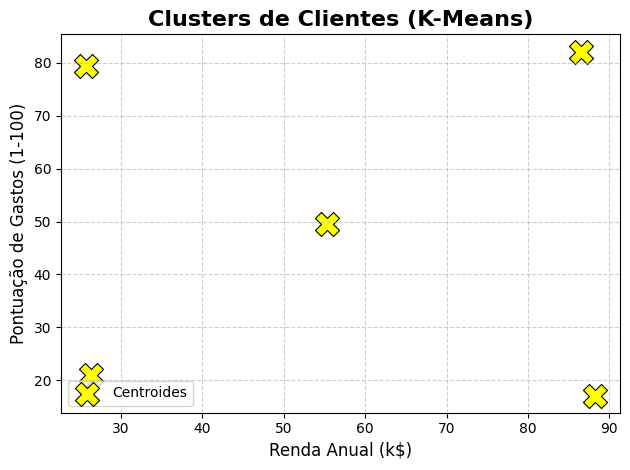

In [10]:
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1],
            s=300, c='yellow', marker='X', label='Centroides', edgecolors='black', linewidth=0.8)

plt.title('Clusters de Clientes (K-Means)', fontsize=16, fontweight='bold')
plt.xlabel('Renda Anual (k$)', fontsize=12)
plt.ylabel('Pontuação de Gastos (1-100)', fontsize=12)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()